# Training a small image GAN

What do discriminator and generator losses reveal during a short adversarial run?

I train a fully connected GAN on eight-by-eight digits. The experiment includes alternating updates, detached discriminator inputs and a nearest-training-image check for generated samples. The small model is intended for understanding training dynamics.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import digits_data, image_grid, seed_everything

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "10_adversarial_generation"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Real images and two networks

Real image intensities are mapped to minus one through one to match the generator's tanh output. The discriminator returns logits. Binary cross-entropy with logits combines a numerically stable sigmoid with the loss.

In [5]:
from deep_projects.models import Generator, Discriminator

data = digits_data(8)
images = data.train.tensors[0] * 2 - 1
loader = DataLoader(
    TensorDataset(images),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(1031),
)
generator, discriminator = Generator(), Discriminator()
generator_optimizer = torch.optim.Adam(
    generator.parameters(), lr=0.0005, betas=(0.5, 0.999)
)
discriminator_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.0005, betas=(0.5, 0.999)
)
print(inspect.getsource(Generator))
print(inspect.getsource(Discriminator))
fixed_noise = torch.randn(8, 16)

class Generator(nn.Module):
    def __init__(self, latent=16):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(latent, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 64),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.layers(noise).view(-1, 1, 8, 8)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Flatten(), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))

    def forward(self, images):
        return self.layers(images)



## Alternating optimization

Discriminator updates see detached fake images. Generator updates freeze discriminator parameters while keeping the differentiable path through its input. Losses are sample-weighted means per epoch. The epoch budget is fixed before inspecting generated images.

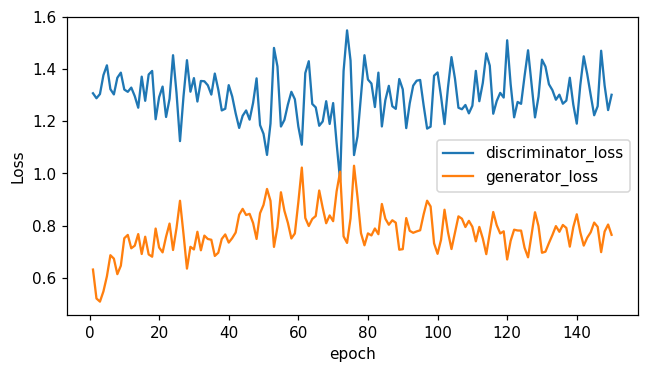

In [7]:
history = []
for epoch in range(12 if QUICK else 150):
    discriminator_total, generator_total, count = 0.0, 0.0, 0
    for (real,) in loader:
        batch_size = len(real)
        discriminator_optimizer.zero_grad(set_to_none=True)
        fake = generator(torch.randn(batch_size, 16)).detach()
        real_loss = F.binary_cross_entropy_with_logits(
            discriminator(real), torch.ones(batch_size, 1)
        )
        fake_loss = F.binary_cross_entropy_with_logits(
            discriminator(fake), torch.zeros(batch_size, 1)
        )
        discriminator_loss = real_loss + fake_loss
        discriminator_loss.backward()
        discriminator_optimizer.step()
        for parameter in discriminator.parameters():
            parameter.requires_grad_(False)
        generator_optimizer.zero_grad(set_to_none=True)
        fake = generator(torch.randn(batch_size, 16))
        generator_loss = F.binary_cross_entropy_with_logits(
            discriminator(fake), torch.ones(batch_size, 1)
        )
        generator_loss.backward()
        generator_optimizer.step()
        for parameter in discriminator.parameters():
            parameter.requires_grad_(True)
        discriminator_total += float(discriminator_loss.detach()) * batch_size
        generator_total += float(generator_loss.detach()) * batch_size
        count += batch_size
    history.append(
        {
            "epoch": epoch + 1,
            "discriminator_loss": discriminator_total / count,
            "generator_loss": generator_total / count,
        }
    )
frame = pd.DataFrame(history)
assert np.isfinite(frame.to_numpy()).all()
frame.plot(x="epoch", y=["discriminator_loss", "generator_loss"], figsize=(6, 3.5))
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig(output / "loss.png", dpi=140)
plt.show()

## Samples and nearest training neighbors

Nearest neighbors in pixel space are a limited memorization diagnostic. The distance is not a generation-quality metric. A short run can produce smooth or repeated samples even when both adversarial losses remain finite.

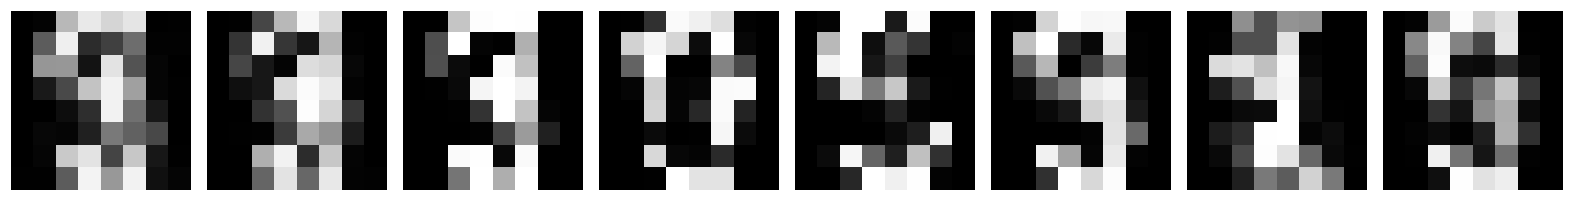

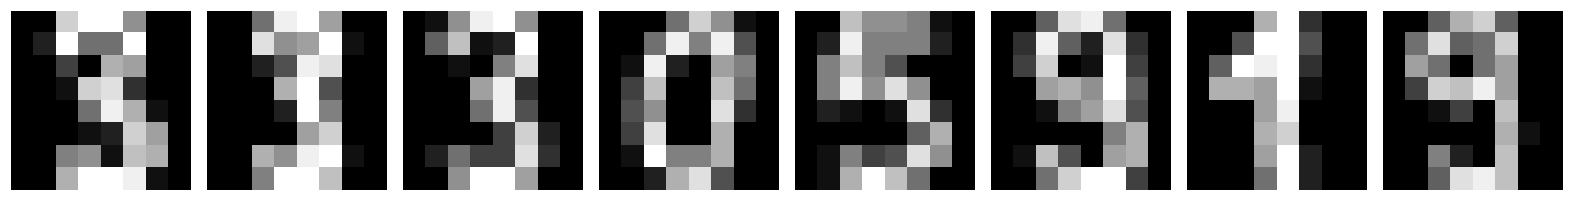

{'epochs': 150, 'final_losses': {'epoch': 150, 'discriminator_loss': 1.3014710750863192, 'generator_loss': 0.7650233483358789}, 'nearest_training_distance_mean': 3.675536632537842, 'generated_pairwise_distance_mean': 4.780156135559082, 'quality_metric_measured': False}


In [9]:
generator.eval()
discriminator.eval()
with torch.inference_mode():
    generated = generator(fixed_noise)
distances = torch.cdist(generated.flatten(1), images.flatten(1))
nearest_distances, neighbors = distances.min(-1)
image_grid((generated + 1) / 2, output / "generated.png")
image_grid((images[neighbors] + 1) / 2, output / "nearest_training.png")
unique_distance = torch.pdist(generated.flatten(1)).mean().item()
results = {
    "epochs": len(history),
    "final_losses": history[-1],
    "nearest_training_distance_mean": float(nearest_distances.mean()),
    "generated_pairwise_distance_mean": unique_distance,
    "quality_metric_measured": False,
}
print(results)

## Reading the result

Adversarial loss is a moving objective because both players change. Its numerical value does not directly rank image quality. Nearest-neighbor distance and pairwise diversity describe this fixed sample batch and do not rule out memorization or mode collapse.

Recorded run: After 150 epochs, the generated sample batch had mean pairwise pixel distance 4.78, compared with 0.97 in the initial short run. The final grid contains more varied strokes, but the model has no held-out distribution-quality score. Its loss curves should be read together with the samples.

In [11]:
result_path = root / "results" / "10_adversarial_generation.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/10_adversarial_generation.json


## Next experiment

Train a convolutional GAN on higher-resolution data and save samples from identical noise at each checkpoint. Add a separately trained held-out classifier for class coverage, documenting that it is only a proxy metric.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week09_adversarial. [Practical DL, HSE, YSDA and Skoltech](https://github.com/yandexdataschool/Practical_DL/tree/fall25).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.